<a href="https://colab.research.google.com/github/ituvtu/aerial-vehicle-detector/blob/main/notebooks/02_train_and_evaluate_detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2: Train, Ablate & Evaluate Aerial Vehicle Detector (`02_train_and_evaluate_detector.ipynb`)

### End-to-End Deep Learning Pipeline for thefourthlaw.ai Test Task

This notebook trains and evaluates an ultra-lightweight neural detector under strict industrial and real-world constraints:
- **Rule 1 (Data Split Isolation)**: Video-level isolation. `eval` (`32179597.mp4`) and `eval_B` (`13763017.mp4`) are strictly held-out in `test` split. Zero test frames are ever seen during training or threshold calibration.
- **Rule 4 (Optical Distance Bands)**: Evaluated across `0–200 m` (near) and `200–400 m` (far) using pinhole camera optics and vehicle physical dimensions.
- **Rule 5 (Edge Model Constraints)**: Custom **YOLO26-Pico-P2** architecture (< 500,000 parameters, P2/4–P3/8–P4/16 high-resolution pyramid, NMS-free dual assignment, DFL-free regression).
- **Rule 6 (Scientific Ablation Study)**: Systematic comparison between `exp1_mosaic` (standard square training with mosaic) vs `exp2_rect_nomosaic` (aspect-ratio preserving rectangular training without mosaic to prevent small-vehicle degradation at 200–400 m).
- **Champion Guard & Append-Only Model Registry**: Non-overwriting immutable model versions in `weights/registry/` protected by validation selection score.

In [1]:
# === SECTION 1: ENVIRONMENT SETUP & DATASET SYNCHRONIZATION ===
import os
import sys
from pathlib import Path
import torch

GITHUB_REPO_URL = "https://github.com/ituvtu/aerial-vehicle-detector.git"
REPO_DIR = Path("/content/aerial-vehicle-detector")

if not REPO_DIR.exists():
    !git clone {GITHUB_REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull --ff-only

%cd {REPO_DIR}

!pip install -q "ultralytics>=8.4.0" "git+https://github.com/ultralytics/CLIP.git" "pandas" "pyyaml" "matplotlib"

print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    !nvidia-smi

import yaml
from src.manifest_manager import ensure_images_available, ensure_raw_eval_video_available, sync_manifest_splits

with open("configs/project_config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

ensure_images_available(
    manifest_path=cfg["paths"]["manifest_path"],
    images_dir=cfg["paths"]["images_dir"],
    bundle_zip_path=cfg["paths"]["images_bundle_zip"],
    bundle_url=cfg.get("remote_data", {}).get("images_bundle_url"),
)
split_counts = sync_manifest_splits()
print("Frames unpacked. Split distribution:", split_counts)

# Ensure raw 30 FPS evaluation video is ready for high-fidelity demo generation
raw_eval_video = ensure_raw_eval_video_available("32179597")
print(f"Raw evaluation video ready: {raw_eval_video} ({raw_eval_video.stat().st_size / 1e6:.1f} MB)")

# Audit curated labels & verify Rule 4 distance coverage
!python scripts/03_audit_labels.py

Cloning into '/content/aerial-vehicle-detector'...
remote: Enumerating objects: 448, done.
remote: Counting objects: 100% (448/448), done.
remote: Compressing objects: 100% (398/398), done.
remote: Total 448 (delta 57), reused 425 (delta 38), pack-reused 0 (from 0)
Receiving objects: 100% (448/448), 4.02 MiB | 20.49 MiB/s, done.
Resolving deltas: 100% (57/57), done.
/content/aerial-vehicle-detector
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.16 | PyTorch: 2.11.0+cu130 | CUDA available: True
GPU Device: NVIDIA A100-SXM4-80GB
Wed Nov  4 22:07:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        

In [2]:
# === SECTION 2: MODEL ARCHITECTURE AUDIT (<500k params, Rule 5) ===
from src.metrics import inspect_and_verify_architecture

arch_report = inspect_and_verify_architecture(
    yaml_path="configs/yolo26_pico_p2.yaml",
    pretrained_weights="yolo26n.pt",
    output_report_path="results/model_architecture_report.json",
    max_params=500_000,
)

print(f"\nArchitecture: {arch_report['model_name']}")
print(f"Unfused Parameters: {arch_report['unfused_params']:,} (<500k limit)")
print(f"Fused Parameters:   {arch_report['fused_params']:,} (<500k limit)")
print(f"Strides:            {arch_report['strides']}")
print("Parameter Breakdown:", arch_report['blocks'])
print("Stem Weight Transfer:", arch_report['pretrained_transfer'])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ no model scale passed. Assuming scale='n'.
layer                                    name                type  gradient  parameters               shape        mu     sigma
    0                     model.0.conv.weight              Conv2d      True         432       [16, 3, 3, 3]  -0.00647     0.112        float32
    1                       model.0.bn.weight         BatchNorm2d      True          16                [16]         1         0        float32
    1                         model.0.bn.bias         BatchNorm2d      True          16                [16]         0         0        float32
    2                             model.0.act                SiLU     False           0          

/usr/local/lib/python3.13/dist-packages/ultralytics/utils/torch_utils.py:575: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  f"{i:>5g}{f'{mn}.{pn}':>40}{mt:>20}{p.requires_grad!r:>10}{p.numel():>12g}{list(p.shape)!s:>20}{p.mean():>10.3g}{p.std():>10.3g}{str(p.dtype).replace('torch.', ''):>15}"


YOLO26_pico_p2 summary: 236 layers, 478,590 parameters, 478,590 gradients, 5.3 GFLOPs
Transferred 58/648 items from pretrained weights
[Architecture Inspection] Saved report to results/model_architecture_report.json

Architecture: YOLO26-Pico-P2
Unfused Parameters: 478,590 (<500k limit)
Fused Parameters:   427,567 (<500k limit)
Strides:            [4.0, 8.0, 16.0]
Parameter Breakdown: {'backbone_layers_0_8': 220448, 'neck_layers_9_20': 162496, 'detect_head_layer_21': 95646}
Stem Weight Transfer: {'source': 'yolo26n.pt', 'transferred_items': 0, 'total_items': 0, 'message': "\x1b[KDownloading https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt to 'yolo26n.pt': 100% ━━━━━━━━━━━━ 5.3MB 219.2MB/s 0.0s"}


WARNING ⚠️ no model scale passed. Assuming scale='n'.
layer                                    name                type  gradient  parameters               shape        mu     sigma
    0                     model.0.conv.weight              Conv2d      True         432       [16, 3, 3, 3]   0.00357      0.11        float32
    1                       model.0.bn.weight         BatchNorm2d      True          16                [16]         1         0        float32
    1                         model.0.bn.bias         BatchNorm2d      True          16                [16]         0         0        float32
    2                             model.0.act                SiLU     False           0                  []         -         -              -
    3                     model.1.conv.weight              Conv2d      True        4608      [32, 16, 3, 3]  0.000268    0.0481        float32
    4                       model.1.bn.weight         BatchNorm2d      True          32                

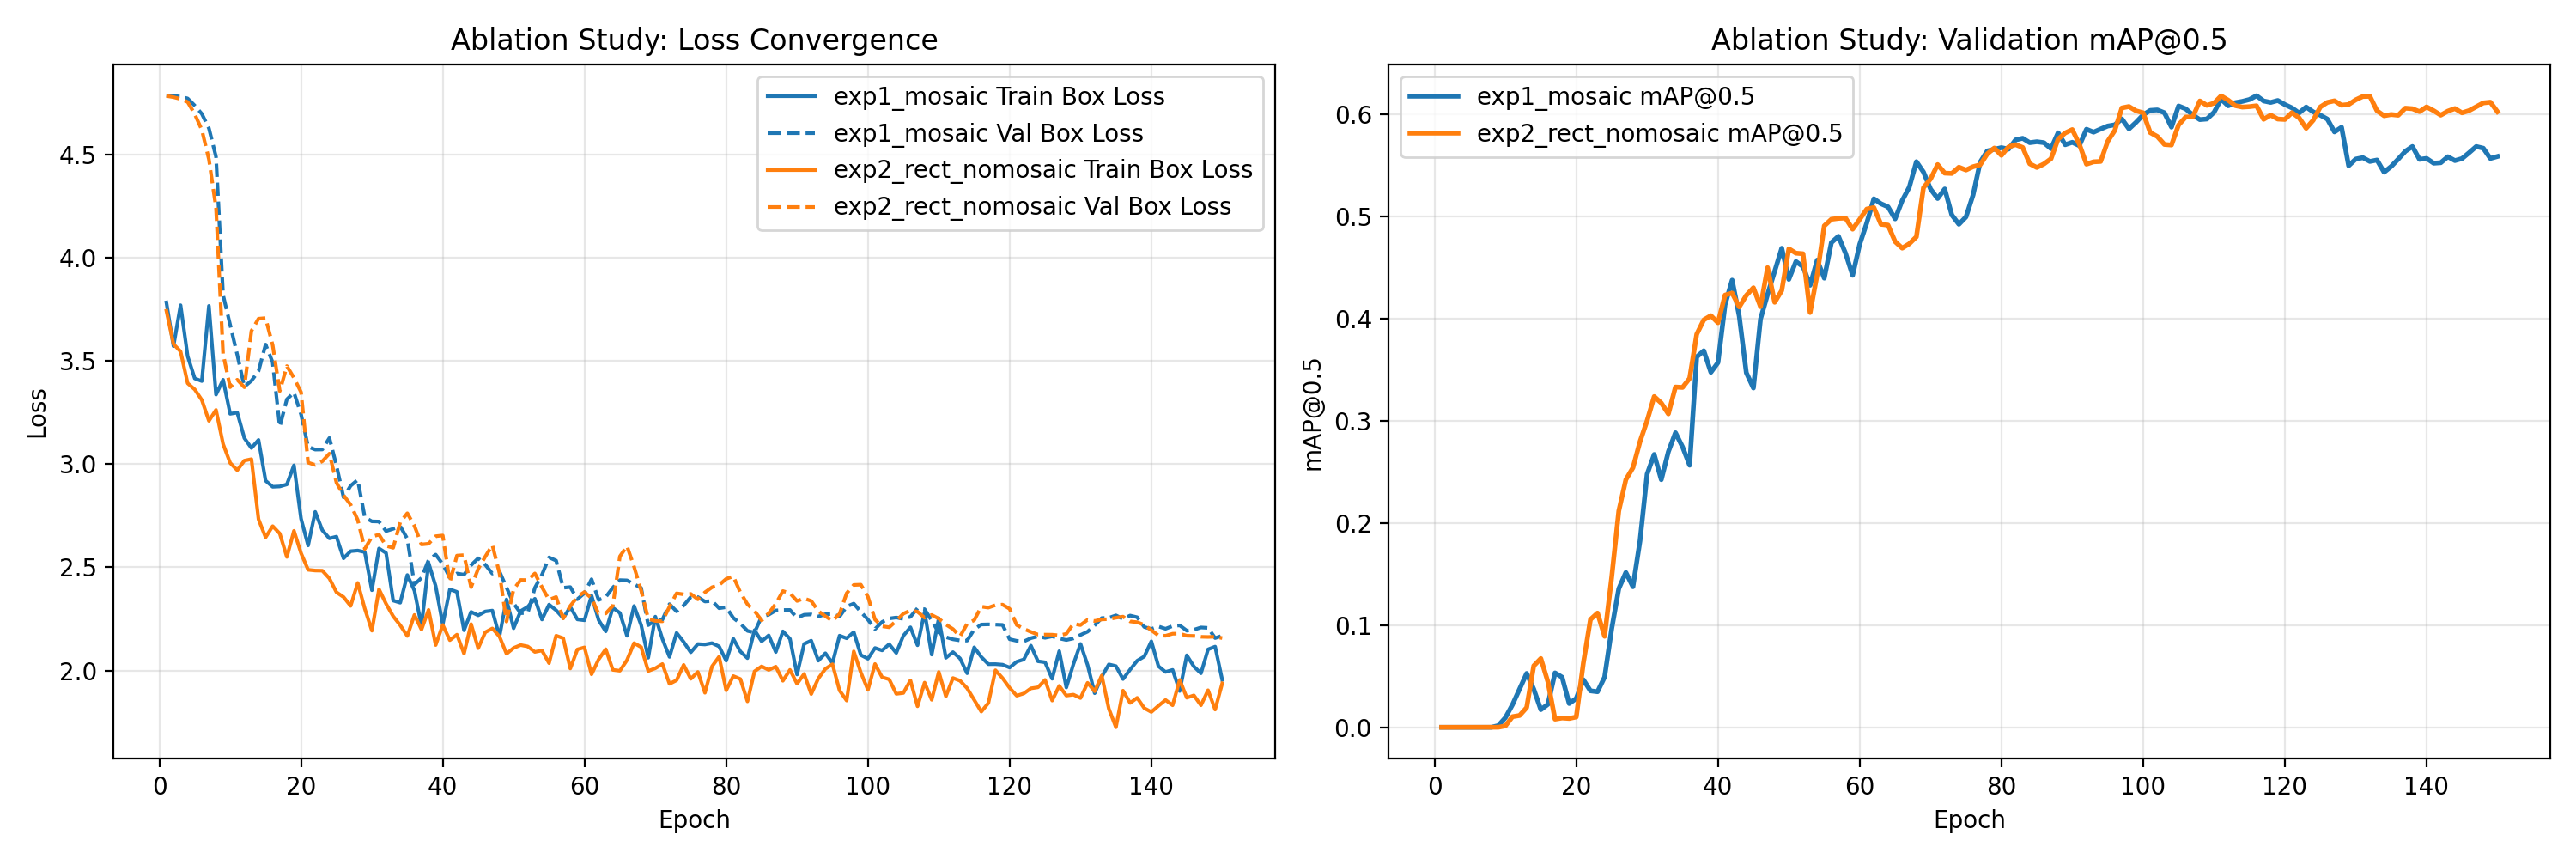

In [3]:
# === SECTION 3: ABLATION TRAINING (exp1_mosaic vs exp2_rect_nomosaic) ===
# Runs both experiments on A100 GPU and calibrates optimal threshold tau* on val split (Rule 1)
!python scripts/04_train.py --mode ablation --epochs 150 --batch 8 --imgsz 1024

from IPython.display import Markdown, display, Image
from pathlib import Path

val_table_p = Path("results/val_ablation_comparison.md")
if val_table_p.exists():
    display(Markdown(val_table_p.read_text(encoding="utf-8")))

curves_p = Path("results/val_ablation_comparison.png")
if curves_p.exists():
    display(Image(filename=str(curves_p)))

In [4]:
# === SECTION 4: DECOUPLED EVALUATION & FULL-FPS VIDEO GENERATION ===
# Fully decoupled: test any checkpoint (or active champion) instantly without retraining!
SELECTED_EXPERIMENT = "auto"  # "auto" (uses Champion Guard winner), or "exp2_rect_nomosaic", "exp1_mosaic"

eval_cmd = "python scripts/05_evaluate.py"
if SELECTED_EXPERIMENT != "auto":
    eval_cmd += f" --weights weights/{SELECTED_EXPERIMENT}_best.pt --calibration weights/calibration_val_{SELECTED_EXPERIMENT}.json"

!{eval_cmd}

eval_summary_p = Path("results/eval_summary_table.md")
if eval_summary_p.exists():
    display(Markdown(eval_summary_p.read_text(encoding="utf-8")))

demo_video_p = Path("results/eval_demo_32179597_full_fps.mp4")
if demo_video_p.exists():
    print(f"\nFull 30.0 FPS Evaluation Video generated: {demo_video_p} ({demo_video_p.stat().st_size / 1e6:.2f} MB)")

[Evaluation] Using calibrated validation threshold: tau* = 0.25 (from calibration_val.json)
[Evaluation] Testing on held-out test clips: ['eval', 'eval_B'] (64 total frames)
[Evaluation] Running inference on 64 held-out test frames (imgsz=1024, rect=True) ...
[Evaluation] Saved metrics and summary tables to /content/aerial-vehicle-detector/results and /content/aerial-vehicle-detector/results/evaluations/m001_20261104T221721Z
[Evaluation] Saved 8 sample crops to /content/aerial-vehicle-detector/results/eval_samples
[Evaluation] Rendered 1-FPS test comparison video: /content/aerial-vehicle-detector/results/eval_gt_vs_pred_1fps.mp4

[Evaluation] Rendering Full 30.0 FPS Demo Video on 32179597.mp4 ...
[Evaluation] Successfully rendered 918 frames at 30.0 FPS to: /content/aerial-vehicle-detector/results/eval_demo_32179597_full_fps.mp4


# Evaluation Results: YOLO26-Pico-P2 on Held-Out Test Split (Rule 1 & Rule 4)

**Model ID**: `m001` | **Weights SHA**: `ec0238fb` | **Parameters**: 427,567 fused (<500k limit)
**Latency**: 19.5 ms mean (51.2 FPS), P95 = 19.2 ms (<33ms real-time: `True`)
**Confidence Threshold**: $\tau^* = 0.25$ (calibrated on val split)

### Test Split Performance Across Optical Distance Bands

| Distance Band | Target Distance | GT Vehicles | True Positives (TP) | False Positives (FP) | False Negatives (FN) | Detection Rate (Recall) | Precision | F1 Score | mAP@0.5 | TTFD (s) | False Alarms / min |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0-200m** | 0–200 m (near) | 441 | 25 | 115 | 416 | 5.7% | 17.9% | 8.6% | 0.1488 | 2.52s | 107.81 |
| **200-400m** | 200–400 m (far) | 352 | 52 | 82 | 300 | 14.8% | 38.8% | 21.4% | 0.1672 | 0.02s | 76.88 |
| **overall_0_400m** | 0–400 m (target task) | 793 | 77 | 197 | 716 | 9.7% | 28.1% | 14.4% | 0.1396 | 2.52s | 184.69 |
| **>400m** | >400 m (ambient background) | 46 | 1 | 13 | 45 | 2.2% | 7.1% | 3.3% | 0.0337 | 18.02s | 12.19 |
| **overall_all** | All Distances (0–∞ m) | 839 | 78 | 210 | 761 | 9.3% | 27.1% | 13.8% | 0.1201 | 2.52s | 196.88 |

### Per-Clip Performance Breakdown (Rule 1 & Rule 4)

| Clip Role | Video ID | Frames | 0–200m Recall | 200–400m Recall | 0–400m F1 | mAP@0.5 | TTFD Delay |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **eval** | `32179597` | 31 | 8.2% | 100.0% | 5.2% | 0.0348 | 5.02s |
| **eval_B** | `13763017` | 33 | 5.1% | 14.8% | 17.5% | 0.3806 | 0.02s |



Full 30.0 FPS Evaluation Video generated: results/eval_demo_32179597_full_fps.mp4 (60.01 MB)


In [5]:
# === SECTION 5: PACKAGE & DOWNLOAD DELIVERABLES BUNDLE ===
import datetime
import zipfile
from pathlib import Path

timestamp = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
bundle_zip = Path(f"colab_results_bundle_{timestamp}.zip")

include_dirs = [Path("weights"), Path("results"), Path("assets"), Path("data/registry")]

with zipfile.ZipFile(bundle_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder in include_dirs:
        if folder.exists():
            for item in folder.rglob("*"):
                if item.is_file() and not item.name.endswith(".mp4") and item.stat().st_size < 50_000_000:
                    zf.write(item, arcname=item.as_posix())

print(f"Packaged deliverables bundle: {bundle_zip} ({bundle_zip.stat().st_size / 1e6:.2f} MB)")

try:
    from google.colab import files
    files.download(str(bundle_zip))
    print("Download triggered in browser.")
except (ImportError, Exception) as exc:
    print(f"Running locally or download skipped: {exc}. Bundle saved at {bundle_zip}")

Packaged deliverables bundle: colab_results_bundle_20261104T221823Z.zip (39.47 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered in browser.
